<a href="https://colab.research.google.com/github/Parvez152977/SMS_Spam_Detection-Naive_Bayes_-_Logistic_Regression-/blob/main/SMS_spam_detectin(Siyma_Aketer_Logistic_regression).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
file_path ='/content/drive/MyDrive/Machine_learning_dataset/SMSSpamCollection'

df = pd.read_csv(
    file_path,
    sep="\t",
    header=None,
    names=["Label", "Message"]
)

df.head()

,Label,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
df.shape

(5572, 2)

In [5]:
df.describe()

,Label,Message
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30


In [6]:
df.isnull().sum()

,0
Label,0
Message,0


In [7]:
df.duplicated().sum()

np.int64(403)

In [8]:
df["Label"].value_counts()

,count
Label,
ham,4825
spam,747


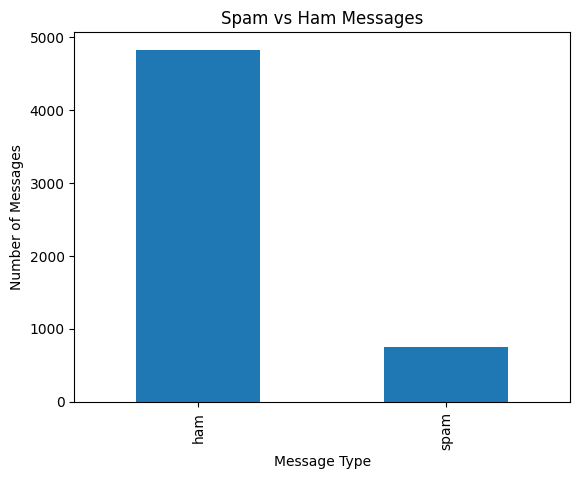

In [9]:
df["Label"].value_counts().plot(kind="bar")

plt.title("Spam vs Ham Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.show()

In [10]:
X = df["Message"]
y = df["Label"]

In [11]:
print(X.head())
print(y.head())

0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: Message, dtype: object
0     ham
1     ham
2    spam
3     ham
4     ham
Name: Label, dtype: object


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [13]:
print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

Training Data: 4457
Testing Data: 1115


In [14]:
cv = CountVectorizer()

X_train = cv.fit_transform(X_train)
X_test = cv.transform(X_test)

In [15]:
print(X_train.shape)
print(X_test.shape)

(4457, 7702)
(1115, 7702)


In [16]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model Training Complete!")

Model Training Complete!


In [17]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

Model Accuracy: 0.9883408071748879


In [18]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       966
        spam       1.00      0.91      0.95       149

    accuracy                           0.99      1115
   macro avg       0.99      0.96      0.97      1115
weighted avg       0.99      0.99      0.99      1115



confusion matrix

In [19]:
cm = confusion_matrix(y_test, y_pred, labels=["ham", "spam"])

print(cm)

[[966   0]
 [ 13 136]]


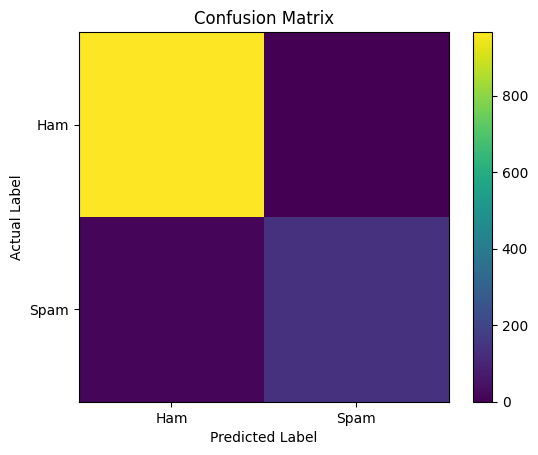

In [20]:
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks([0, 1], ["Ham", "Spam"])
plt.yticks([0, 1], ["Ham", "Spam"])
plt.colorbar()
plt.show()

New SMS Prediction

In [21]:
message = ["Congratulations! You won a free prize"]

message_vector = cv.transform(message)

prediction = model.predict(message_vector)

print("Prediction:", prediction[0])

Prediction: ham


In [22]:
message = ["Hey, how are you?"]

message_vector = cv.transform(message)

prediction = model.predict(message_vector)

print("Prediction:", prediction[0])

Prediction: ham


 Model Performance Graph

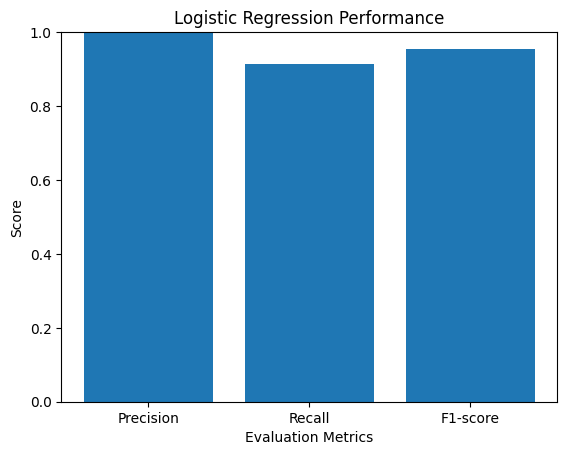

In [23]:
report = classification_report(y_test, y_pred, output_dict=True)

scores = [
    report["spam"]["precision"],
    report["spam"]["recall"],
    report["spam"]["f1-score"]
]

metrics = ["Precision", "Recall", "F1-score"]

plt.bar(metrics, scores)
plt.title("Logistic Regression Performance")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.show()

Final Project Summary

In [24]:
print("SMS Spam Detection Project")
print("---------------------------")
print("Algorithm: Logistic Regression")
print("Total Messages:", len(df))
print("Training Messages:", X_train.shape[0])
print("Testing Messages:", X_test.shape[0])
print("Accuracy:", accuracy)
print(classification_report(y_test, y_pred))

SMS Spam Detection Project
---------------------------
Algorithm: Logistic Regression
Total Messages: 5572
Training Messages: 4457
Testing Messages: 1115
Accuracy: 0.9883408071748879
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       966
        spam       1.00      0.91      0.95       149

    accuracy                           0.99      1115
   macro avg       0.99      0.96      0.97      1115
weighted avg       0.99      0.99      0.99      1115

